# 310.3. The galaxy luminosity function from photometric redshifts

<div style="max-width:300px; float: left; margin-right: 1em">

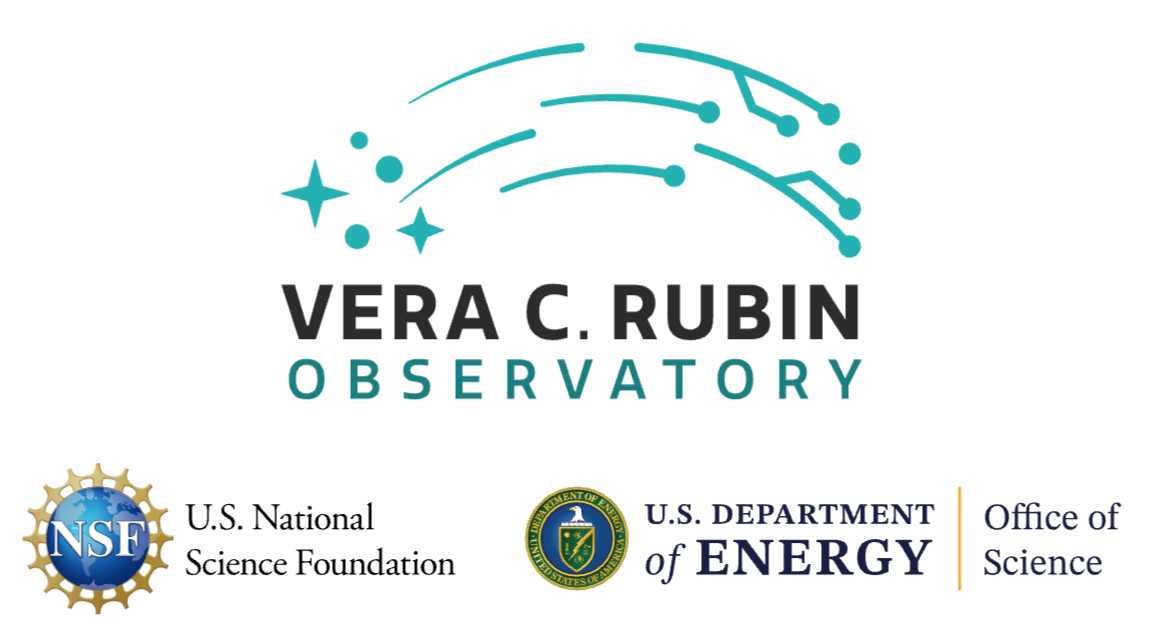

</div>

For the Rubin Science Platform at data.lsst.cloud.\
Data Release: [Data Preview 2](https://dp2.lsst.io)\
Container Size: Large\
LSST Science Pipelines version: r30.0.11\
Last verified to run: 2026-10-23\
Repository: [github.com/lsst/tutorial-notebooks](https://github.com/lsst/tutorial-notebooks)\
DOI: [10.11578/rubin/dc.20250909.20](https://doi.org/10.11578/rubin/dc.20250909.20)

**Learning objective:** Use DP2's photometric redshifts to construct a galaxy luminosity function with the 1/V_max estimator, propagate photo-z uncertainty into it with a Monte Carlo resampling, fit a Schechter function to it with `emcee`, and compare the result across DP2's six photo-z estimators.

**LSST data products:** `Object`, `object_photoz` (LSDB)

**Packages:** `lsst.rsp`, `lsdb`, `astropy.cosmology`, `scipy`, `emcee`, `numpy`, `pandas`, `matplotlib`

**Credit:**
Originally developed by the Rubin Community Science team.
Please consider acknowledging them if this notebook is used for the preparation of journal articles, software releases, or other notebooks.

**Get Support:**
Everyone is encouraged to ask questions or raise issues in the
<a href="https://community.lsst.org/c/support">Support Category</a>
of the Rubin Community Forum.
Rubin staff will respond to all questions posted there.

## 1. Introduction

The galaxy luminosity function describes the number density of galaxies per unit volume, as a function of luminosity. It is a fundamental observational constraint on galaxy formation and evolution. Computing the galaxy luminosity function requires an absolute magnitude for each galaxy, and the survey volume within which a galaxy of that magnitude could have been detected. Both require a distance, meaning redshift estimates are essential. DP2's `object_photoz` catalogue (introduced in 310.1) provides photometric redshift estimates and their associated uncertainties for galaxies across the survey.

This notebook builds the i-band luminosity function with the classic $1/V_{\mathrm{max}}$ estimator ([Schmidt 1968](https://doi.org/10.1086/149446)): each galaxy is weighted by the inverse of the maximum comoving volume within which it would still be bright enough to enter the sample, correcting for the fact that a flux-limited survey sees intrinsically faint galaxies over a smaller volume than bright ones. Photo-z uncertainty is propagated into the result with a Monte Carlo resampling of each galaxy's redshift. A Schechter function ([Schechter 1976](https://doi.org/10.1086/154079)) is then fit to the result with `emcee`'s MCMC sampler, giving posterior uncertainties on its parameters. Finally, the whole process is repeated for each of DP2's six photo-z estimators, to see how much the derived luminosity function depends on which one is used.

### 1.1. Import packages

Import common scientific analysis packages `numpy`, `pandas`, and `matplotlib`.

Import LSST Science Pipelines package utilities for remote data access, `lsst.rsp`, and `lsst.utils.plotting` for the standard Rubin plot style.

Import `lsdb` and `upath` to access DP2's native photometric redshift catalog, and `astropy.cosmology` to convert angular and apparent measurements to physical units.

Import `emcee` to fit the Schechter function.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lsdb
from upath import UPath

from astropy.cosmology import Planck18 as cosmo
import astropy.units as u

import emcee

from lsst.rsp import RSPDiscovery
from lsst.utils.plotting import set_rubin_plotstyle

set_rubin_plotstyle()
plt.rcParams["figure.dpi"] = 150
np.random.seed(1)

### 1.2. Define parameters

Set up the TAP service client used for data access, the sky position and radius of the DDF_COSMOS field, and the i-band flux limit used throughout this notebook.

In [2]:
discovery = RSPDiscovery("dp2")
tap_service = discovery.get_tap_client()

field_ra, field_dec = 150.1, 2.1
field_radius = 0.7
mag_limit = 23.0

## 2. Query for galaxy photometry

Query the `Object` table in the DDF_COSMOS field, the same field used in 310.1 and 310.2, for a clean sample of resolved galaxies brighter than the i-band flux limit used throughout this cross-match. Each photo-z estimator tested below reuses this same photometric sample.

In [3]:
query = f'''SELECT objectId, coord_ra, coord_dec, i_cModelMag
FROM dp2.Object
WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec), CIRCLE('ICRS', {field_ra}, {field_dec}, {field_radius}))=1
  AND refExtendedness = 1
  AND i_cModel_flag = 0
  AND i_cModelFlux/i_cModelFluxErr > 10
  AND i_cModelMag < {mag_limit}
'''

job = tap_service.submit_job(query)
job.run()
job.wait(phases=["COMPLETED", "ERROR"])
assert job.phase == "COMPLETED"
dp2_tab = job.fetch_result().to_table()
job.delete()

print(f"Retrieved {len(dp2_tab)} DP2 objects")

Retrieved 53546 DP2 objects


## 3. Set up the $1/V_{\mathrm{max}}$ estimator

For a flux-limited sample, a galaxy with absolute magnitude $M$ can only be seen out to the redshift $z_{\mathrm{max}}$ at which its apparent magnitude would equal the survey's flux limit. Beyond that, it would have dropped out of the sample entirely. $V_{\mathrm{max}}$ is the comoving volume enclosed within $\min(z_{\mathrm{max}}, z_{\mathrm{survey\,limit}})$, and weighting each galaxy by $1/V_{\mathrm{max}}$ corrects the raw galaxy counts for this effect.

Both the distance modulus and the comoving volume are monotonic functions of redshift, so precompute them on a fine redshift grid and invert by interpolation.

In [4]:
z_grid = np.linspace(0.01, 2.0, 2000)
distmod_grid = cosmo.distmod(z_grid).value

solid_angle_sr = 2 * np.pi * (1 - np.cos(np.radians(field_radius)))
comoving_volume_grid = (
    cosmo.comoving_volume(z_grid).to(u.Mpc**3).value
    * (solid_angle_sr / (4 * np.pi))
)

z_survey_lo, z_survey_hi = 0.05, 1.0
comoving_volume_floor = np.interp(z_survey_lo, z_grid, comoving_volume_grid)


def abs_mag_from_z(app_mag, z):
    """Convert an apparent magnitude to an absolute magnitude at redshift z."""
    return app_mag - np.interp(z, z_grid, distmod_grid)


def vmax_from_abs_mag(abs_mag):
    """Return Vmax [Mpc^3], the maximum comoving volume within which a galaxy
    of this absolute magnitude stays brighter than the survey flux limit,
    clipped to the survey's redshift range."""
    target_distmod = mag_limit - abs_mag
    z_max = np.interp(target_distmod, distmod_grid, z_grid)
    z_max = np.clip(z_max, z_survey_lo, z_survey_hi)
    vmax = np.interp(z_max, z_grid, comoving_volume_grid) - comoving_volume_floor
    return vmax

## 4. Build the luminosity function for one photo-z estimator

Join the photometric sample against DP2's photo-z catalog for each estimator `lsdb` (see also tutorial 310.1). `fetch_photoz_sample` performs this join for each estimator; `build_luminosity_function` then runs the Monte Carlo resampling and $1/V_{\mathrm{max}}$ weighting on the result. Resample each galaxy's redshift estimate `n_mc` times from a Gaussian with width set by the estimator's own 68% credible interval, and rebuild the luminosity function for each estimator. Combine the resulting bin-to-bin scatter across resamples (capturing photo-z uncertainty) in quadrature with Poisson counting uncertainty for the final error bars.

In [5]:
mag_bins = np.arange(-24, -18.5, 0.5)
mag_bin_centers = 0.5 * (mag_bins[:-1] + mag_bins[1:])
bin_width = mag_bins[1] - mag_bins[0]


def fetch_photoz_sample(estimator, dp2_tab):
    """Join the DP2 photometry against one photo-z estimator's redshift and
    uncertainty columns from the object_photoz LSDB catalog, and restrict to
    galaxies with a usable redshift in the survey's range."""
    dp2 = dp2_tab.to_pandas()
    dp2_renamed = dp2.rename(columns={"coord_ra": "ra", "coord_dec": "dec"})
    dp2_lsdb = lsdb.from_dataframe(dp2_renamed, catalog_name="object")

    base_path = UPath("/rubin/lsdb_data/dp2")
    z_col = f"{estimator}_z_median"
    lo_col = f"{estimator}_z_err68_low"
    hi_col = f"{estimator}_z_err68_high"
    pz_cat = lsdb.open_catalog(
        base_path / "object_photoz", columns=["objectId", "ra", "dec", z_col, lo_col, hi_col])
    pz_cat_cone = pz_cat.cone_search(
        ra=field_ra, dec=field_dec, radius_arcsec=field_radius * 3600.0)

    joined = pz_cat_cone.join(
        dp2_lsdb, left_on="objectId", right_on="objectId", suffix_method="all_columns")
    df = pd.DataFrame(joined.compute())
    df = df.rename(columns={
        f"{z_col}_object_photoz": "zphot",
        f"{lo_col}_object_photoz": "z_err_lo",
        f"{hi_col}_object_photoz": "z_err_hi",
        "i_cModelMag_object": "i_cModelMag",
    })
    cols = ["zphot", "z_err_lo", "z_err_hi", "i_cModelMag"]
    df[cols] = df[cols].astype("float64")
    df["z_sigma"] = (df["z_err_hi"] - df["z_err_lo"]) / 2.0
    df = df[(df["zphot"] > z_survey_lo) & (df["zphot"] < z_survey_hi)
            & (df["z_sigma"] > 0)].reset_index(drop=True)
    return df


def build_luminosity_function(df, n_mc=50):
    """Build a 1/Vmax-weighted luminosity function from a photo-z sample,
    propagating photo-z uncertainty by Monte Carlo resampling of each
    galaxy's redshift. A galaxy whose resampled zmax clips to the survey's
    lower redshift bound has no accessible volume in range, so it
    contributes zero weight rather than a diverging one."""
    rng = np.random.RandomState(1)
    phi_mc = np.zeros((n_mc, len(mag_bin_centers)))
    counts_mc = np.zeros((n_mc, len(mag_bin_centers)))

    for mc_draw in range(n_mc):
        z_draw = np.clip(rng.normal(df["zphot"].values, df["z_sigma"].values), 0.01, 1.5)
        abs_mag = abs_mag_from_z(df["i_cModelMag"].values, z_draw)
        vmax = vmax_from_abs_mag(abs_mag)
        weight = np.divide(1.0, vmax, out=np.zeros_like(vmax), where=vmax > 0)
        for bin_idx in range(len(mag_bin_centers)):
            sel = (abs_mag >= mag_bins[bin_idx]) & (abs_mag < mag_bins[bin_idx + 1])
            counts_mc[mc_draw, bin_idx] = sel.sum()
            if sel.sum() > 0:
                phi_mc[mc_draw, bin_idx] = weight[sel].sum() / bin_width

    phi = phi_mc.mean(axis=0)
    phi_mc_scatter = phi_mc.std(axis=0)
    mean_counts = counts_mc.mean(axis=0)
    phi_poisson = np.divide(
        phi, np.sqrt(mean_counts), out=np.zeros_like(phi), where=mean_counts > 0)
    phi_err = np.sqrt(phi_mc_scatter**2 + phi_poisson**2)

    return pd.DataFrame({
        "abs_mag": mag_bin_centers, "phi": phi, "phi_err": phi_err,
        "n_galaxies": mean_counts,
    })

Print the resulting binned luminosity function for GPz as a quick look before fitting a Schechter function to it in Section 5.

In [6]:
gpz_df = fetch_photoz_sample("gpz", dp2_tab)
gpz_lf = build_luminosity_function(gpz_df)
print(gpz_lf)

Computing Catalog:   0%|          | 0/16 [00:00<?, ?it/s]

   abs_mag       phi   phi_err  n_galaxies
0   -23.75  0.000050  0.000005      153.54
1   -23.25  0.000192  0.000010      587.92
2   -22.75  0.000580  0.000018     1773.16
3   -22.25  0.001316  0.000026     4025.18
4   -21.75  0.002194  0.000033     6712.88
5   -21.25  0.002885  0.000039     8631.62
6   -20.75  0.003596  0.000054     7800.36
7   -20.25  0.003885  0.000071     5438.38
8   -19.75  0.003937  0.000089     3454.42
9   -19.25  0.004100  0.000133     2201.84


## 5. Fit a Schechter function with `emcee`

The Schechter function is

$$\phi(M) = 0.4 \ln(10) \, \phi^* \, 10^{0.4(\alpha + 1)(M^* - M)} \exp\left(-10^{0.4(M^* - M)}\right)$$

with three free parameters: $\phi^*$, the overall normalization; $M^*$, the characteristic magnitude marking the exponential cutoff at the bright end; and $\alpha$, the power-law slope at the faint end. Fit it in log-space, since $\phi$ spans several orders of magnitude across the fitted range, and only fit magnitudes brighter than $M = -19$, since $1/V_{\mathrm{max}}$ weighting becomes increasingly unstable for the faintest, most volume-limited galaxies.

`emcee` needs a log-posterior function (a flat prior over a broad, physically reasonable range here, plus a Gaussian log-likelihood comparing the model to the binned data) and an ensemble of walkers started in a small cloud around a reasonable initial guess. Use 32 walkers, several times the number of free parameters, run for 3000 steps each. Discard the first 500 steps as burn-in, before the chain has settled into the posterior, and thin the remainder by a factor of 10 when flattening it, since adjacent steps in an MCMC chain are correlated. Section 5.1 checks this choice directly with a trace plot.

In [7]:
def schechter_log10(mags, log_phi_star, m_star, alpha):
    """Evaluate log10 of the Schechter luminosity function at given magnitudes."""
    phi_star = 10**log_phi_star
    x = 10**(0.4 * (m_star - mags))
    schechter = 0.4 * np.log(10) * phi_star * x**(alpha + 1) * np.exp(-x)
    return np.log10(schechter)


def log_prior(theta):
    """Flat prior over a broad, physically reasonable range for the three
    Schechter parameters; -inf (zero probability) outside that range."""
    log_phi_star, m_star, alpha = theta
    if -6 < log_phi_star < 1 and -25 < m_star < -18 and -3 < alpha < 1:
        return 0.0
    return -np.inf


def log_likelihood(theta, mags, log_phi_obs, log_phi_err_obs):
    """Gaussian log-likelihood comparing the Schechter model to the binned,
    log-space luminosity function data."""
    model = schechter_log10(mags, *theta)
    if not np.all(np.isfinite(model)):
        return -np.inf
    return -0.5 * np.sum(((log_phi_obs - model) / log_phi_err_obs) ** 2)


def log_posterior(theta, mags, log_phi_obs, log_phi_err_obs):
    """Log-posterior: the flat prior plus the Gaussian log-likelihood."""
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, mags, log_phi_obs, log_phi_err_obs)


def fit_schechter(lf_table, mag_limit_bright=-19.0, n_walkers=32, n_steps=3000, n_burn=500):
    """Fit a Schechter function to a luminosity function table with emcee.

    Parameters
    ----------
    lf_table : pandas.DataFrame
        Output of build_luminosity_function, with abs_mag, phi, and phi_err.
    mag_limit_bright : float
        Only fit magnitudes brighter than this.
    n_walkers, n_steps, n_burn : int
        emcee ensemble sampler settings.

    Returns
    -------
    flat_samples : numpy.ndarray
        Burn-in-discarded, thinned, flattened posterior samples, shape (n, 3).
    full_chain : numpy.ndarray
        The raw, undiscarded chain, shape (n_steps, n_walkers, 3), for the
        convergence check in Section 5.1.
    """
    fit_data = lf_table[lf_table["abs_mag"] < mag_limit_bright].reset_index(drop=True)
    mags = fit_data["abs_mag"].values
    log_phi = np.log10(fit_data["phi"].values)
    log_phi_err = fit_data["phi_err"].values / (fit_data["phi"].values * np.log(10))

    ndim = 3
    initial_guess = np.array([-2.5, -21.0, -1.0])
    rng = np.random.RandomState(1)
    start_positions = initial_guess + 1e-2 * rng.randn(n_walkers, ndim)

    sampler = emcee.EnsembleSampler(
        n_walkers, ndim, log_posterior, args=(mags, log_phi, log_phi_err))
    sampler.run_mcmc(start_positions, n_steps, progress=False)

    flat_samples = sampler.get_chain(discard=n_burn, thin=10, flat=True)
    full_chain = sampler.get_chain()
    return flat_samples, full_chain


gpz_samples, gpz_chain = fit_schechter(gpz_lf)
labels = ["log(phi*)", "M*", "alpha"]
for param_idx, label in enumerate(labels):
    lo, med, hi = np.percentile(gpz_samples[:, param_idx], [16, 50, 84])
    print(f"{label}: {med: .3f} +{hi - med: .3f} -{med - lo: .3f}")

log(phi*): -2.276 + 0.010 - 0.010
M*: -21.976 + 0.020 - 0.022
alpha: -0.981 + 0.014 - 0.015


### 5.1. Check convergence

A trace plot shows each walker's position for each parameter as a function of step number. After burn-in, a well-converged chain should fluctuate around a stable range of values, with no systematic drift and all walkers sampling similar regions of parameter space.

Text(0.5, 0, 'step')

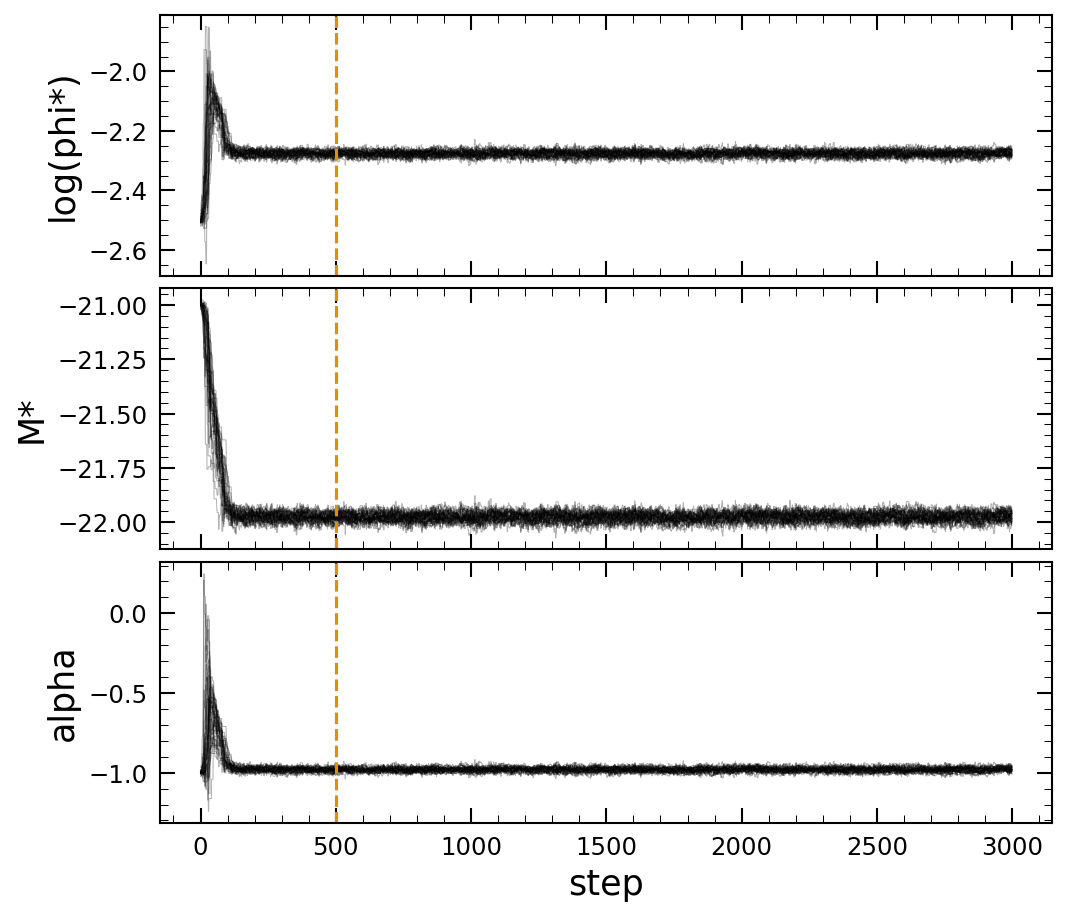

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(7, 6), sharex=True, layout="constrained")
for param_idx, (ax, label) in enumerate(zip(axes, labels)):
    ax.plot(gpz_chain[:, :, param_idx], color="k", alpha=0.3, linewidth=0.5)
    ax.axvline(500, color="C1", linestyle="--", linewidth=1.5)
    ax.set_ylabel(label)
axes[-1].set_xlabel("step")

> Figure: Trace of all 32 walkers for each Schechter parameter, fitting the GPz-derived luminosity function. The dashed line marks the burn-in cutoff (step 500) discarded before flattening the chain. All walkers mix around a common region with no systematic drift, indicating convergence.

## 6. Compare across DP2's photo-z estimators

Repeat Sections 4 and 5 for each of DP2's six photo-z estimators, and compare both the resulting luminosity functions and their fitted Schechter parameters directly.

BPZ is template-fitting based, matching observed photometry against a library of galaxy spectral energy distribution templates; the other five (DNF, FlexZBoost, GPz, kNN, TPZ) are machine-learning regression algorithms trained on a reference redshift sample. [Charles et al. 2026 (RTN-124)](https://rtn-124.lsst.io/), describe the methodology used to produce DP2's photometric redshift catalogue, including a comparison of the six algorithms' performance against a reference spectroscopic and grism sample.

In [9]:
estimators = ["bpz", "dnf", "fzboost", "gpz", "knn", "tpz"]
estimator_colors = {
    estimator: f"C{estimator_idx}" for estimator_idx, estimator in enumerate(estimators)
}

results = {}
for estimator in estimators:
    df = fetch_photoz_sample(estimator, dp2_tab)
    lf_table = build_luminosity_function(df, n_mc=20)
    samples, _ = fit_schechter(lf_table)
    results[estimator] = {"lf": lf_table, "samples": samples}
    print(f"{estimator}: done")

estimators = sorted(estimators, key=lambda e: np.median(results[e]["samples"][:, 1]))

Computing Catalog:   0%|          | 0/16 [00:00<?, ?it/s]

bpz: done


Computing Catalog:   0%|          | 0/16 [00:00<?, ?it/s]

dnf: done


Computing Catalog:   0%|          | 0/16 [00:00<?, ?it/s]

...

gpz: done


Computing Catalog:   0%|          | 0/16 [00:00<?, ?it/s]

knn: done


Computing Catalog:   0%|          | 0/16 [00:00<?, ?it/s]

tpz: done


Plot the resulting luminosity function for each of the six estimators together, as a line with a shaded 95% credible region, to compare their shapes directly.

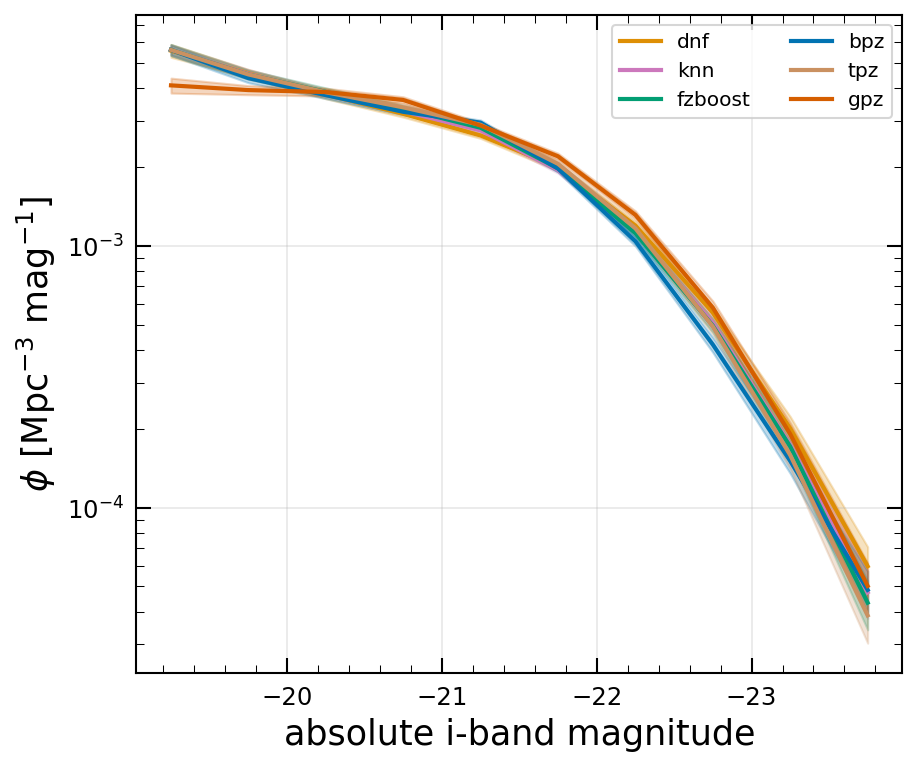

In [10]:
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
for estimator in estimators:
    lf_table = results[estimator]["lf"]
    color = estimator_colors[estimator]
    phi = lf_table["phi"].values
    phi_lo95 = np.clip(phi - 1.96 * lf_table["phi_err"].values, 1e-7, None)
    phi_hi95 = phi + 1.96 * lf_table["phi_err"].values

    ax.plot(lf_table["abs_mag"], phi, color=color, label=estimator)
    ax.fill_between(lf_table["abs_mag"], phi_lo95, phi_hi95, color=color, alpha=0.25)
ax.set_yscale("log")
ax.set_xlabel("absolute i-band magnitude")
ax.set_ylabel(r"$\phi$ [Mpc$^{-3}$ mag$^{-1}$]")
ax.invert_xaxis()
ax.legend(ncol=2)
ax.grid(True, alpha=0.3)

> Figure: The i-band luminosity function for each of DP2's six photo-z estimators, in the DDF_COSMOS field. Lines show the 1/Vmax-weighted number density per magnitude bin; shaded bands show the 95% credible interval, combining Monte Carlo photo-z resampling and Poisson counting uncertainty.

Plot the posterior median and 95% credible interval for each of the three Schechter function parameters across the six estimators,

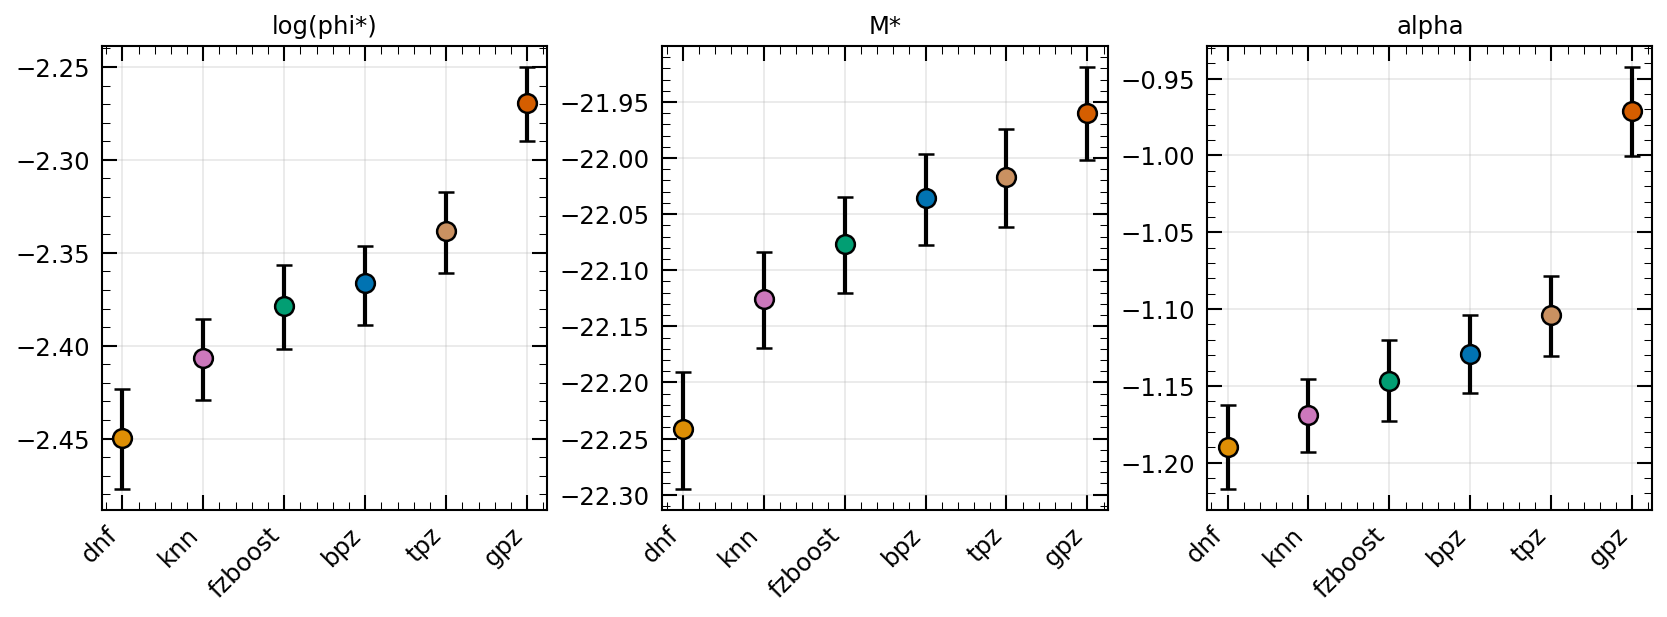

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
param_labels = ["log(phi*)", "M*", "alpha"]

for ax, param_index, label in zip(axes, range(3), param_labels):
    for estimator_idx, estimator in enumerate(estimators):
        samples = results[estimator]["samples"][:, param_index]
        lo95, median, hi95 = np.percentile(samples, [2.5, 50, 97.5])
        ax.errorbar([estimator_idx], [median], yerr=[[median - lo95], [hi95 - median]],
                    fmt="o", color=estimator_colors[estimator], markeredgecolor="k",
                    markeredgewidth=1.2, markersize=9, capsize=4, ecolor="k")
    ax.set_xticks(range(len(estimators)))
    ax.set_xticklabels(estimators, rotation=45, ha="right")
    ax.set_title(label)
    ax.grid(True, alpha=0.3)

> Figure: Median and 95% credible interval for each fitted Schechter parameter (log $\phi^*$, $M^*$, $\alpha$), by photo-z estimator, ordered by increasing $M^*$.

Differences in the credible intervals indicate how sensitive the inferred Schechter parameters are to the choice of photo-z estimator. This extends the comparison in 310.2 from redshift estimates themselves to a physical quantity derived from them.

## Summary

This notebook builds the galaxy luminosity function from DP2 photometry using the 1/Vmax estimator, propagates photo-z uncertainty via Monte Carlo resampling of each galaxy's redshift, and fits a Schechter function with ``emcee``. Comparing the luminosity functions and fitted Schechter parameters across DP2's six photometric redshift estimators provides a way to assess how the choice of photo-z algorithm affects the inferred luminosity function and its uncertainties.